# Lösung: AnySplat-Gaussians korrekt in die OKVIS-Szene legen

Dieses Notebook enthält die Lösung für das Center-Crop-Problem aus `intergratepipelines_gsrotations.py` und vergleicht
sie direkt mit dem aktuellen Stand. Die Tests, die zu dieser Lösung geführt haben, stehen in
`crop_loesungen_test.ipynb`.

**Die Lösung in einem Satz:** Jede Ansicht wird als rektifizierter Crop an AnySplat gegeben, mit
ihrer eigenen OKVIS-Pose in die Welt gelegt, und die Position jeder Gaussian kommt aus dem Mesh. Nur wo das Mesh
nicht getroffen wird, kommt sie aus AnySplats Tiefe, die vorher affin ans Mesh angepasst wurde.

Die Schritte pro Mesh-Zentrum:

1. Zwei Frames wählen, in denen das Zentrum sichtbar ist, nicht am Bildrand liegt und die 2 bis 8 Frames
   auseinander sind. Frames, die zur Auswertung zurückgehalten werden, sind ausgeschlossen.
2. Für jeden Frame eine virtuelle Kamera bauen, die auf das Zentrum schaut, und den Crop per Homographie erzeugen.
   Die Crop-Größe passt sich dem Abstand an, damit die ganze Kugel um das Zentrum im Bild ist.
3. Beide Crops zusammen an AnySplat geben, ohne Voxelisierung, damit jede Gaussian zu einem Pixel gehört.
4. Pro Ansicht: die AnySplat-Punkte affin auf die Mesh-Punkte derselben Pixel fitten. Das korrigiert Brennweite,
   Skala und Verzerrung auf einmal.
5. Pro Ansicht: jede Gaussian, deren Pixel das Mesh trifft, auf den Treffpunkt setzen. Die übrigen behalten die
   affin korrigierte Position. Alles mit der echten OKVIS-Pose dieses Frames in die Welt legen.
6. Nur Gaussians innerhalb von 1,25 × `vol_radius` um das Zentrum behalten.
7. Optional: kurz gegen die Trainingsbilder nachoptimieren.

**Kernel:** `anysplat`. Das Notebook schreibt nichts auf die Platte. Laufzeit etwa 3 Minuten auf einer RTX 4090.

In [1]:
import os, sys, io, contextlib, math, time, gc
from pathlib import Path
import numpy as np
import torch
import cv2
import trimesh
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

ROOT = Path.cwd()
if not (ROOT / "AnySplat").exists():
    ROOT = Path("/home/hannah/Documents/GitHub/2026-schmid-luis-mt")
sys.path.insert(0, str(ROOT / "AnySplat"))
from src.model.model.anysplat import AnySplat
from src.misc.sh_rotation import rotate_sh
from gsplat import rasterization

DATA = ROOT / "data/SABERGUIDE/KITTI/seq10"
POSE_PATH = DATA / "gt_poses_seq10/kitti_gt_poses/10/poses.txt"
IMG_DIR = DATA / "cam0/data"
CALIB_PATH = ROOT / "data/SABERGUIDE/KITTI_ODOMETRY/dataset/sequences/10/calib.txt"
MESH_PATH = DATA / "kitti_seq10_gt/mesh_kf000001.ply"

FRAME_START, FRAME_END = 0, 34
VOL_RADIUS = 4.0          # wie im Skript
R_LACTOR = 1.25           # Kugel etwas größer als vol_radius, damit Nachbarzentren überlappen
NET = 448                 # Eingabegröße AnySplat
CROP_MIN, CROP_MAX = 224, 370
HOLDOUT = lambda f: f % 4 == 2   # diese Frames sieht AnySplat nie, sie dienen nur zur Auswertung
SEED = 0

DEVICE = "cuda"
HW = NET * NET
torch.set_grad_enabled(False)
np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams["figure.dpi"] = 110

ModuleNotFoundError: No module named 'jaxtyping'

## 1. Daten und Geometrie

In [2]:
def load_K(path):
    for line in open(path):
        if line.startswith("P2:"):
            P = np.array(line.split()[1:], dtype=np.float64).reshape(3, 4)
    K, *_ = cv2.decomposeProjectionMatrix(P)
    return K / K[2, 2]

K = load_K(CALIB_PATH)
raw = np.loadtxt(POSE_PATH).reshape(-1, 3, 4)
poses = np.tile(np.eye(4), (len(raw), 1, 1)); poses[:, :3, :] = raw          # T_world_cam
poses = poses[FRAME_START:FRAME_END]
images = [np.asarray(Image.open(IMG_DIR / f"{i:06d}.png").convert("RGB")) for i in range(FRAME_START, FRAME_END)]
H_IMG, W_IMG = images[0].shape[:2]
NF = len(images)
IS_HOLDOUT = np.array([HOLDOUT(f) for f in range(NF)])
EVAL = np.where(IS_HOLDOUT)[0]
TRAIN = np.where(~IS_HOLDOUT)[0]

mesh = trimesh.load(MESH_PATH)
intersector = trimesh.ray.ray_pyembree.RayMeshIntersector(mesh)
print("Frames:", NF, "| Holdout:", EVAL.tolist())


def to_cam(pts, k):
    T = np.linalg.inv(poses[k]); return pts @ T[:3, :3].T + T[:3, 3]

def project(pts, k):
    pc = to_cam(pts, k); z = pc[:, 2]
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.stack([K[0, 0] * pc[:, 0] / z + K[0, 2], K[1, 1] * pc[:, 1] / z + K[1, 2]], 1), z

def in_image(uv, z=None):
    ok = (uv[:, 0] >= 0) & (uv[:, 0] < W_IMG) & (uv[:, 1] >= 0) & (uv[:, 1] < H_IMG)
    return ok if z is None else ok & (z > 0.5)

def rays(uv, k):
    d = np.c_[uv, np.ones(len(uv))] @ np.linalg.inv(K).T
    d /= np.linalg.norm(d, axis=1, keepdims=True)
    d = d @ poses[k][:3, :3].T
    return np.ascontiguousarray(np.broadcast_to(poses[k][:3, 3], d.shape)), np.ascontiguousarray(d)

def raycast(o, d):
    hits = np.full(d.shape, np.nan)
    if len(d):
        locs, ir, _ = intersector.intersects_location(o, d, multiple_hits=False)
        hits[ir] = locs
    return hits

def mesh_hits(uv, k, valid=None):
    h = raycast(*rays(uv, k))
    if valid is not None:
        h[~valid] = np.nan
    return h

def mesh_depth(k):
    g = np.stack(np.meshgrid(np.arange(W_IMG), np.arange(H_IMG)), -1).reshape(-1, 2).astype(float)
    return to_cam(mesh_hits(g, k), k)[:, 2].reshape(H_IMG, W_IMG)

MESH_DEPTH = {k: mesh_depth(k) for k in EVAL}

Frames: 34 | Holdout: [2, 6, 10, 14, 18, 22, 26, 30]


## 2. Zentren und Sichtbarkeit

`fetch_centroids()` wie im Skript. Sichtbar ist ein Zentrum nur, wenn es vor der Kamera liegt (`z > 0`) und nicht vom
Mesh verdeckt wird. Das Skript prüft beides nicht.

In [3]:
def fetch_centroids(pts, radius):
    centers = np.empty((0, 3))
    for p in pts:
        if len(centers) and (((centers - p) ** 2).sum(1) <= radius ** 2).any():
            continue
        centers = np.vstack([centers, p])
    return centers

centers = fetch_centroids(mesh.triangles_center.astype(np.float64), VOL_RADIUS)
UV = np.zeros((NF, len(centers), 2))
vis = np.zeros((NF, len(centers)), bool)
for f in range(NF):
    uv, z = project(centers, f)
    UV[f] = uv
    idx = np.where(in_image(uv, z))[0]
    o, d = rays(uv[idx], f)
    h = raycast(o, d)
    occluded = np.linalg.norm(h - o, axis=1) < np.linalg.norm(centers[idx] - o, axis=1) - 0.5
    vis[f, idx[~occluded]] = True
print(len(centers), "Zentren")

37 Zentren


## 3. Frame-Auswahl

**Skript:** erster und letzter Crop nach `sorted()` über Strings. Das ist weder der erste noch der letzte Frame, und
das Zentrum liegt oft am Bildrand.

**Lösung:** zwei Frames, 2 bis 8 Frames auseinander, in denen das Zentrum möglichst weit innen liegt und nicht zu
weit weg ist (Strafterm ab 25 m) und nicht zu nah (unter 4 m).

In [4]:
def frames_script(j):
    names = sorted(f"center{j}image{k}" for k in np.where(vis[:, j] & ~IS_HOLDOUT)[0])
    if len(names) < 2:
        return None
    return int(names[0].split("image")[1]), int(names[-1].split("image")[1])

def frames_solution(j, gap=(2, 8)):
    fr = np.where(vis[:, j] & ~IS_HOLDOUT)[0]
    if len(fr) < 2:
        return None
    du = np.abs(UV[fr, j, 0] - K[0, 2]) / (W_IMG / 2)
    dv = np.abs(UV[fr, j, 1] - K[1, 2]) / (H_IMG / 2)
    dist = np.linalg.norm(centers[j] - poses[fr][:, :3, 3], axis=1)
    score = np.maximum(du, dv) + 0.02 * np.maximum(dist - 25, 0) + 0.05 * np.maximum(4 - dist, 0)
    best = None
    for a in range(len(fr)):
        for b in range(a + 1, len(fr)):
            if gap[0] <= fr[b] - fr[a] <= gap[1] and (best is None or score[a] + score[b] < best[0]):
                best = (score[a] + score[b], fr[a], fr[b])
    if best is None:
        a, b = sorted(fr[np.argsort(score)[:2]])
        return a, b
    return best[1], best[2]

## 4. Crops

`axis_crop()` ist der bisherige Weg (`extract_window_no_padding()` + `process_image_helper()`).
`rect_crop()` ist die virtuelle Kamera. Beide liefern für jedes der 448×448 Pixel die Koordinate im Originalbild
(`src`), daraus werden später die Mesh-Treffer bestimmt.

Die Crop-Größe der Lösung ist so gewählt, dass die Kugel um das Zentrum in den Crop passt:
`crop = 2 · R · 1.1 · fx / Abstand`, begrenzt auf 224 bis 370 px.

In [5]:
JJ, II = np.meshgrid(np.arange(NET), np.arange(NET))

def axis_crop(img, uc, vc, crop=224):
    half = crop // 2
    cxi = int(np.clip(int(uc), half, W_IMG - half)); cyi = int(np.clip(int(vc), half, H_IMG - half))
    x1, y1 = cxi - half, cyi - half
    net = np.asarray(Image.fromarray(img[y1:y1 + crop, x1:x1 + crop]).resize((NET, NET)))
    s = crop / NET
    src = np.stack([x1 + (JJ + 0.5) * s - 0.5, y1 + (II + 0.5) * s - 0.5], -1).reshape(-1, 2)
    return dict(img=net, src=src, valid=np.ones(HW, bool), x1=x1, y1=y1, crop=crop, f_true=K[0, 0] / s)

def rect_crop(img, uc, vc, crop):
    f_v = K[0, 0] * NET / crop
    uc = np.clip(uc, crop // 2, W_IMG - crop // 2)
    vc = np.clip(vc, min(crop, H_IMG) // 2, H_IMG - min(crop, H_IMG) // 2)
    z = np.linalg.inv(K) @ np.array([uc, vc, 1.0]); z /= np.linalg.norm(z)
    x = np.cross([0.0, 1.0, 0.0], z); x /= np.linalg.norm(x)
    y = np.cross(z, x)
    R_cv = np.stack([x, y, z], axis=1)                                   # virtuell -> echt
    K_v = np.array([[f_v, 0, NET / 2], [0, f_v, NET / 2], [0, 0, 1]])
    Hm = K @ R_cv @ np.linalg.inv(K_v)                                   # virtuelles Pixel -> Originalpixel
    net = cv2.warpPerspective(img, Hm, (NET, NET), flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP)
    s = Hm @ np.stack([JJ.ravel(), II.ravel(), np.ones(HW)])
    src = (s[:2] / s[2]).T
    return dict(img=net, src=src, valid=in_image(src), R_cv=R_cv, crop=crop, f_true=f_v)

def adaptive_crop_size(j, k):
    dist = np.linalg.norm(centers[j] - poses[k][:3, 3])
    return int(np.clip(2 * VOL_RADIUS * R_LACTOR * 1.1 * K[0, 0] / dist, CROP_MIN, CROP_MAX))

## 5. AnySplat

In [6]:
model = AnySplat.from_pretrained("lhjiang/anysplat").to(DEVICE).eval()
model.encoder.distill = False
model.encoder.cfg.voxelize = False       # eine Gaussian pro Pixel

def run_anysplat(net_imgs):
    x = torch.stack([torch.from_numpy(np.ascontiguousarray(c)).permute(2, 0, 1).float() / 255.0
                     for c in net_imgs])[None].to(DEVICE)
    with contextlib.redirect_stdout(io.StringIO()):
        out = model.encoder(x, global_step=0, visualization_dump=None)
    g = out.gaussians
    assert g.means.shape[1] == len(net_imgs) * HW
    return dict(means=g.means[0].double().cpu().numpy(), cov=g.covariances[0].double().cpu().numpy(),
                harm=g.harmonics[0].float(), opac=g.opacities[0].double().cpu().numpy(),
                c2w=out.pred_context_pose["extrinsic"][0].double().cpu().numpy(),
                Kn=out.pred_context_pose["intrinsic"][0].double().cpu().numpy())

def any_cam(res, v):
    # AnySplat-Welt -> Kamerasystem von AnySplat-Ansicht v (extrinsic ist camera-to-world)
    T = np.linalg.inv(res["c2w"][v])
    return res["means"][v * HW:(v + 1) * HW] @ T[:3, :3].T + T[:3, 3], T[:3, :3]

def polar_R(L):
    U, _, Vt = np.linalg.svd(L)
    if np.linalg.det(U @ Vt) < 0:
        U[:, -1] *= -1
    return U @ Vt

def rot_harm(harm, R):
    return rotate_sh(harm, torch.tensor(R, dtype=torch.float32, device=DEVICE))

def focal_diag(res, v, f_true):
    return np.diag([res["Kn"][v, 0, 0] * NET / f_true, res["Kn"][v, 1, 1] * NET / f_true, 1.0])

def pack(means, cov, harm, opac, keep, center_id):
    keep = keep & np.isfinite(means[:, 0])
    kt = torch.from_numpy(keep).to(DEVICE)
    return dict(means=means[keep].astype(np.float32), cov=cov[keep].astype(np.float32),
                harm=harm[kt].half().cpu(), opac=opac[keep].astype(np.float32),
                cid=np.full(keep.sum(), center_id, np.int32))

## 6. Aktueller Stand

Der aktuelle Stand aus `intergratepipelines_gsrotations.py`, so nah wie möglich an `pipeline_foward()`: achsparalleler 224er-Crop, Frame-Auswahl per String-Sortierung, beide
Ansichten über die relative Pose von AnySplat, Drehung der z-Achse auf den Strahl der Crop-Mitte
(Zeile 427 bis 439), Skala aus dem Mesh-Abstand des Zentrums, Kugel mit `vol_radius`.

Drei Unterschiede zum Skript: Die Translation wird aus `[0:3, 3]` gelesen, statt `z * 2` wird die geschätzte
Brennweite verwendet, und die modifizierten Encoder-Hooks (`pixeldepth1`, `extrinsics1`, `intrinsicsfxy`) fehlen,
weil ihr Code nicht im Repo liegt. Ohne die ersten beiden Korrekturen wäre der Vergleich nicht sinnvoll, der
aktuelle Stand würde dann noch schlechter abschneiden.

In [7]:
CENTER_WIN = ((np.abs(II - NET // 2) <= 5) & (np.abs(JJ - NET // 2) <= 5)).ravel()

def rotation_matrix_from_vectors(a, b):                  # aus dem Skript
    a = a / np.linalg.norm(a); b = b / np.linalg.norm(b)
    v = np.cross(a, b); c = np.dot(a, b); s = np.linalg.norm(v)
    if s == 0:
        return np.identity(3)
    vx = np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])
    return np.identity(3) + vx + vx @ vx * ((1 - c) / s ** 2)

def place_aktuell(j):
    ks = frames_script(j)
    if ks is None:
        return None, None
    crops = [axis_crop(images[k], *UV[k, j]) for k in ks]
    res = run_anysplat([c["img"] for c in crops])
    k1, c1 = ks[0], crops[0]
    d = np.linalg.inv(K) @ np.array([c1["x1"] + 112, c1["y1"] + 112, 1.0])
    M = np.linalg.inv(rotation_matrix_from_vectors(d, np.array([0, 0, 1.0]))) @ focal_diag(res, 0, c1["f_true"])
    T = np.linalg.inv(res["c2w"][0])
    q = (res["means"] @ T[:3, :3].T + T[:3, 3]) @ M.T
    h = mesh_hits(c1["src"], k1)
    w = CENTER_WIN & np.isfinite(h[:, 0])
    if w.sum() < 10:
        w = np.isfinite(h[:, 0])
    s = np.median(np.linalg.norm(to_cam(h, k1)[w], axis=1) / np.linalg.norm(q[:HW][w], axis=1))
    Twc = poses[k1]
    means = (s * q) @ Twc[:3, :3].T + Twc[:3, 3]
    L = Twc[:3, :3] @ (s * M) @ T[:3, :3]
    keep = (np.linalg.norm(means - centers[j], axis=1) <= VOL_RADIUS) & (res["opac"] > 0.05)
    out = pack(means, L @ res["cov"] @ L.T, rot_harm(res["harm"], polar_R(L)), res["opac"], keep, j)
    return out, dict(ks=ks, crops=crops)

## 7. Lösung

Pro Ansicht einzeln. `A` ist die affine Abbildung vom AnySplat-Kamerasystem ins echte Kamerasystem, gefittet auf alle
Pixel, die das Mesh treffen (Least Squares, viermal die schlechtesten 20 % verworfen). Treffer-Pixel werden danach
auf den Mesh-Punkt gesetzt, ihre Kovarianz mit dem Tiefenverhältnis skaliert.

In [8]:
def fit_affine(pc, target, iters=4, keep=0.8):
    X = np.c_[pc, np.ones(len(pc))]
    sel = np.ones(len(X), bool)
    for _ in range(iters):
        A, *_ = np.linalg.lstsq(X[sel], target[sel], rcond=None)
        e = np.linalg.norm(X @ A - target, axis=1)
        sel = e <= np.quantile(e, keep)
    return A.T, np.median(e[sel])

def place_loesung(j):
    ks = frames_solution(j)
    if ks is None:
        return None, None
    crops = [rect_crop(images[k], *UV[k, j], adaptive_crop_size(j, k)) for k in ks]
    res = run_anysplat([c["img"] for c in crops])
    parts = []
    for v, (c, k) in enumerate(zip(crops, ks)):
        sl = slice(v * HW, (v + 1) * HW)
        pc, Rv = any_cam(res, v)
        h = mesh_hits(c["src"], k, c["valid"])
        Pc = to_cam(h, k)
        hit = np.isfinite(h[:, 0])
        fit = hit & (res["opac"][sl] > 0.1)
        if fit.sum() < 200:
            continue
        A, _ = fit_affine(pc[fit][::3], Pc[fit][::3])
        pcam = pc @ A[:, :3].T + A[:, 3]
        Twc = poses[k]
        L = Twc[:3, :3] @ A[:, :3] @ Rv
        cov = L @ res["cov"][sl] @ L.T
        # Mesh-Treffer: Position vom Mesh, Größe mit dem Tiefenverhältnis angepasst
        ratio = np.linalg.norm(Pc[hit], axis=1) / np.linalg.norm(pcam[hit], axis=1)
        pcam[hit] = Pc[hit]
        cov[hit] *= (ratio ** 2)[:, None, None]
        means = pcam @ Twc[:3, :3].T + Twc[:3, 3]
        keep = c["valid"] & (res["opac"][sl] > 0.05) & \
               (np.linalg.norm(means - centers[j], axis=1) <= VOL_RADIUS * R_LACTOR)
        parts.append(pack(means, cov, rot_harm(res["harm"][sl], polar_R(L)), res["opac"][sl], keep, j))
    if not parts:
        return None, None
    return merge(parts), dict(ks=ks, crops=crops)

def merge(parts):
    return {key: (torch.cat([p[key] for p in parts]) if key == "harm" else np.concatenate([p[key] for p in parts]))
            for key in parts[0]}

## 8. Ganze Submap aufbauen

In [9]:
def build(place):
    t = time.time()
    parts, info = [], {}
    for j in range(len(centers)):
        g, inf = place(j)
        if g is not None:
            parts.append(g); info[j] = inf
    g = merge(parts)
    print(f"{place.__name__}: {len(g['means']) / 1e6:.2f} Mio Gaussians aus {len(parts)} Zentren, {time.time() - t:.0f} s")
    return g, info

G_B, INFO_B = build(place_aktuell)
G_L, INFO_L = build(place_loesung)
del model; gc.collect(); torch.cuda.empty_cache()

/tmp/ipykernel_979735/2191033474.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  x = torch.stack([torch.from_numpy(np.ascontiguousarray(c)).permute(2, 0, 1).float() / 255.0


place_aktuell: 3.27 Mio Gaussians aus 32 Zentren, 10 s
place_loesung: 2.17 Mio Gaussians aus 32 Zentren, 15 s


## 9. Auswertung auf den Holdout-Frames

Gerendert wird die ganze Submap aus den Posen der Holdout-Frames. Kein Holdout-Frame ging an AnySplat.

- **PSNR (Mesh-Pixel):** über alle Pixel, auf die das Mesh fällt. Löcher zählen als Fehler.
- **Deckung:** Anteil dieser Pixel, die der Render mit Alpha > 0,5 abdeckt.
- **Tiefenfehler:** Median von |Render-Tiefe − Mesh-Tiefe| / Mesh-Tiefe auf den gedeckten Pixeln.

In [10]:
def render(g, k, harm=None, depth=True):
    N = len(g["means"])
    f32 = lambda a: torch.as_tensor(a, dtype=torch.float32, device=DEVICE)
    colors = (harm if harm is not None else g["harm"].to(DEVICE).float()).permute(0, 2, 1).contiguous()
    img, alpha, _ = rasterization(
        means=f32(g["means"]), quats=f32(np.tile([1.0, 0, 0, 0], (N, 1))), scales=f32(np.ones((N, 3))),
        opacities=f32(g["opac"]), colors=colors, viewmats=f32(np.linalg.inv(poses[k]))[None], Ks=f32(K)[None],
        width=W_IMG, height=H_IMG, sh_degree=4, covars=f32(g["cov"]), near_plane=0.1, far_plane=500.0,
        packed=False, rasterize_mode="classic", render_mode="RGB+ED" if depth else "RGB")
    img = img[0].cpu().numpy(); alpha = alpha[0, ..., 0].cpu().numpy()
    rgb = (np.clip(img[..., :3], 0, 1) * 255).astype(np.uint8)
    d = img[..., 3] / np.maximum(alpha, 1e-6) if depth else None
    return rgb, alpha, d

def psnr(a, b, m):
    mse = ((a[m].astype(float) - b[m].astype(float)) ** 2).mean()
    return 10 * np.log10(255 ** 2 / mse)

def evaluate(g, name):
    harm = g["harm"].to(DEVICE).float()
    r = dict(psnr=[], cov=[], depth=[], renders={})
    for k in EVAL:
        rgb, alpha, d = render(g, k, harm)
        m = np.isfinite(MESH_DEPTH[k])
        cm = m & (alpha > 0.5)
        r["psnr"].append(psnr(rgb, images[k], m))
        r["cov"].append(cm.sum() / m.sum())
        r["depth"].append(np.median(np.abs(d[cm] - MESH_DEPTH[k][cm]) / MESH_DEPTH[k][cm]))
        r["renders"][k] = (rgb, alpha, d)
    del harm; torch.cuda.empty_cache()
    print(f"{name:28s} PSNR {np.mean(r['psnr']):5.2f} dB | Deckung {np.mean(r['cov']):.2f} | "
          f"Tiefenfehler {np.mean(r['depth']) * 100:4.1f} %")
    return r

R_B = evaluate(G_B, "aktueller Stand")
R_L = evaluate(G_L, "Lösung")

aktueller Stand              PSNR 16.49 dB | Deckung 0.96 | Tiefenfehler 12.2 %
Lösung                       PSNR 20.28 dB | Deckung 0.97 | Tiefenfehler  2.4 %


In [11]:
print(f"{'Frame':>6s} {'PSNR aktuell':>13s} {'PSNR Lösung':>13s} {'Tiefe aktuell':>13s} {'Tiefe Lösung':>13s}")
for i, k in enumerate(EVAL):
    print(f"{k:6d} {R_B['psnr'][i]:13.2f} {R_L['psnr'][i]:13.2f} {R_B['depth'][i] * 100:12.1f}% {R_L['depth'][i] * 100:12.1f}%")

 Frame  PSNR aktuell   PSNR Lösung Tiefe aktuell  Tiefe Lösung
     2         21.07         21.29         14.0%          1.7%
     6         20.64         20.16         12.8%          1.7%
    10         19.25         20.01         12.4%          2.2%
    14         15.69         20.72         13.1%          3.2%
    18         14.48         20.00         11.3%          4.8%
    22         13.86         20.84         11.2%          3.0%
    26         13.56         19.85         10.0%          1.8%
    30         13.34         19.34         12.4%          1.2%


## 10. Side-by-Side: aktueller Stand gegen Lösung

Drei Holdout-Frames. Pro Frame von oben nach unten:

1. Farbe: echtes Bild, aktueller Stand, Lösung
2. Farbfehler |Render − Bild| (hell = großer Fehler); links die Mesh-Pixel, auf denen gemessen wird
3. Tiefenfehler gegenüber dem Mesh, 0 bis 30 %; links die Mesh-Tiefe

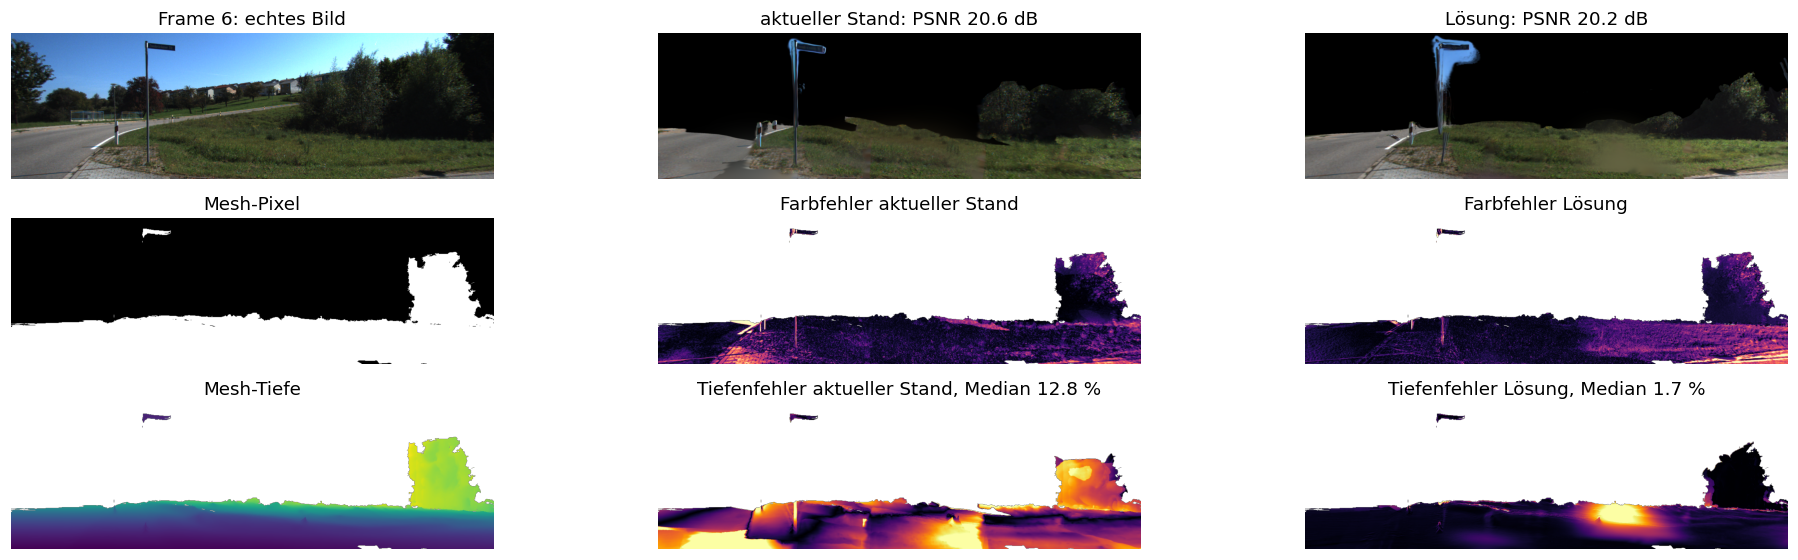

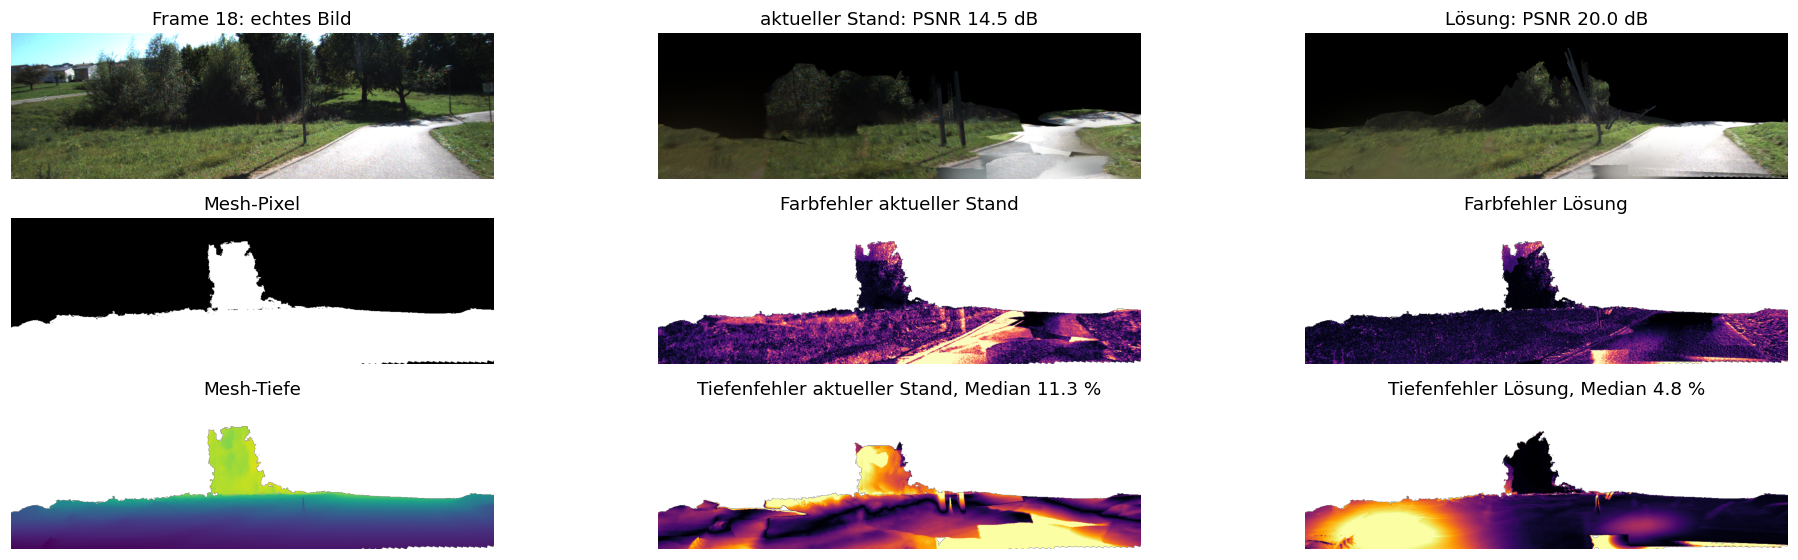

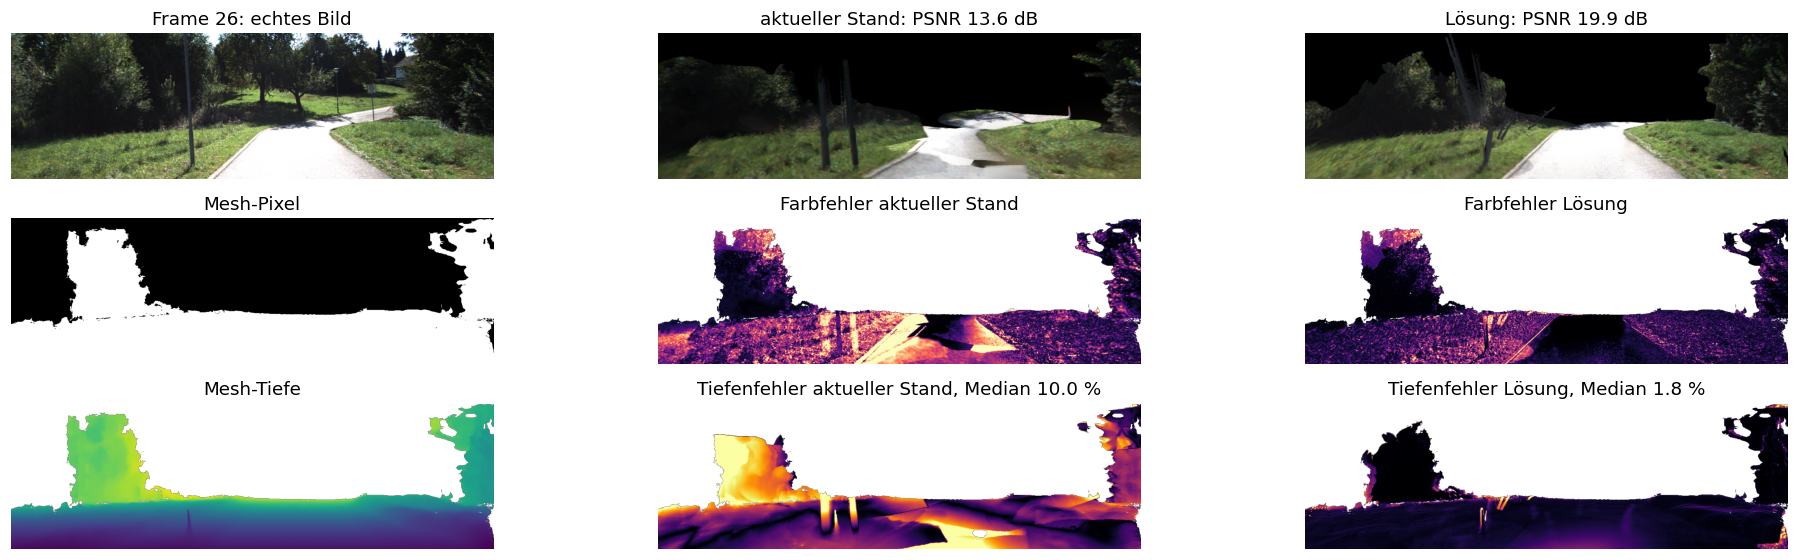

In [12]:
SHOW = [EVAL[1], EVAL[4], EVAL[6]]
for k in SHOW:
    rgbB, aB, dB = R_B["renders"][k]
    rgbL, aL, dL = R_L["renders"][k]
    md_ = MESH_DEPTH[k]
    m = np.isfinite(md_)
    errB = np.abs(rgbB.astype(float) - images[k]).mean(-1); errB[~m] = np.nan
    errL = np.abs(rgbL.astype(float) - images[k]).mean(-1); errL[~m] = np.nan
    deB = np.abs(dB - md_) / md_; deB[~(m & (aB > 0.5))] = np.nan
    deL = np.abs(dL - md_) / md_; deL[~(m & (aL > 0.5))] = np.nan
    i = list(EVAL).index(k)
    fig, ax = plt.subplots(3, 3, figsize=(18, 5.2))
    ax[0, 0].imshow(images[k]); ax[0, 0].set_title(f"Frame {k}: echtes Bild")
    ax[0, 1].imshow(rgbB); ax[0, 1].set_title(f"aktueller Stand: PSNR {R_B['psnr'][i]:.1f} dB")
    ax[0, 2].imshow(rgbL); ax[0, 2].set_title(f"Lösung: PSNR {R_L['psnr'][i]:.1f} dB")
    ax[1, 0].imshow(m, cmap="gray"); ax[1, 0].set_title("Mesh-Pixel")
    ax[1, 1].imshow(errB, cmap="magma", vmin=0, vmax=100); ax[1, 1].set_title("Farbfehler aktueller Stand")
    ax[1, 2].imshow(errL, cmap="magma", vmin=0, vmax=100); ax[1, 2].set_title("Farbfehler Lösung")
    ax[2, 0].imshow(md_, cmap="viridis"); ax[2, 0].set_title("Mesh-Tiefe")
    ax[2, 1].imshow(deB, cmap="inferno", vmin=0, vmax=0.3); ax[2, 1].set_title(f"Tiefenfehler aktueller Stand, Median {R_B['depth'][i]*100:.1f} %")
    ax[2, 2].imshow(deL, cmap="inferno", vmin=0, vmax=0.3); ax[2, 2].set_title(f"Tiefenfehler Lösung, Median {R_L['depth'][i]*100:.1f} %")
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout(); plt.show()

### Einzelnes Zentrum am Bildrand

Hier sieht man den Unterschied am deutlichsten. Gezeigt werden nur die Gaussians eines einzigen Zentrums, gerendert
in den ersten Eingabeframe und in einen Holdout-Frame. Das rote Rechteck ist der Crop, den der aktuelle Stand verwendet, das grüne
Kreuz die Projektion des Mesh-Zentrums.

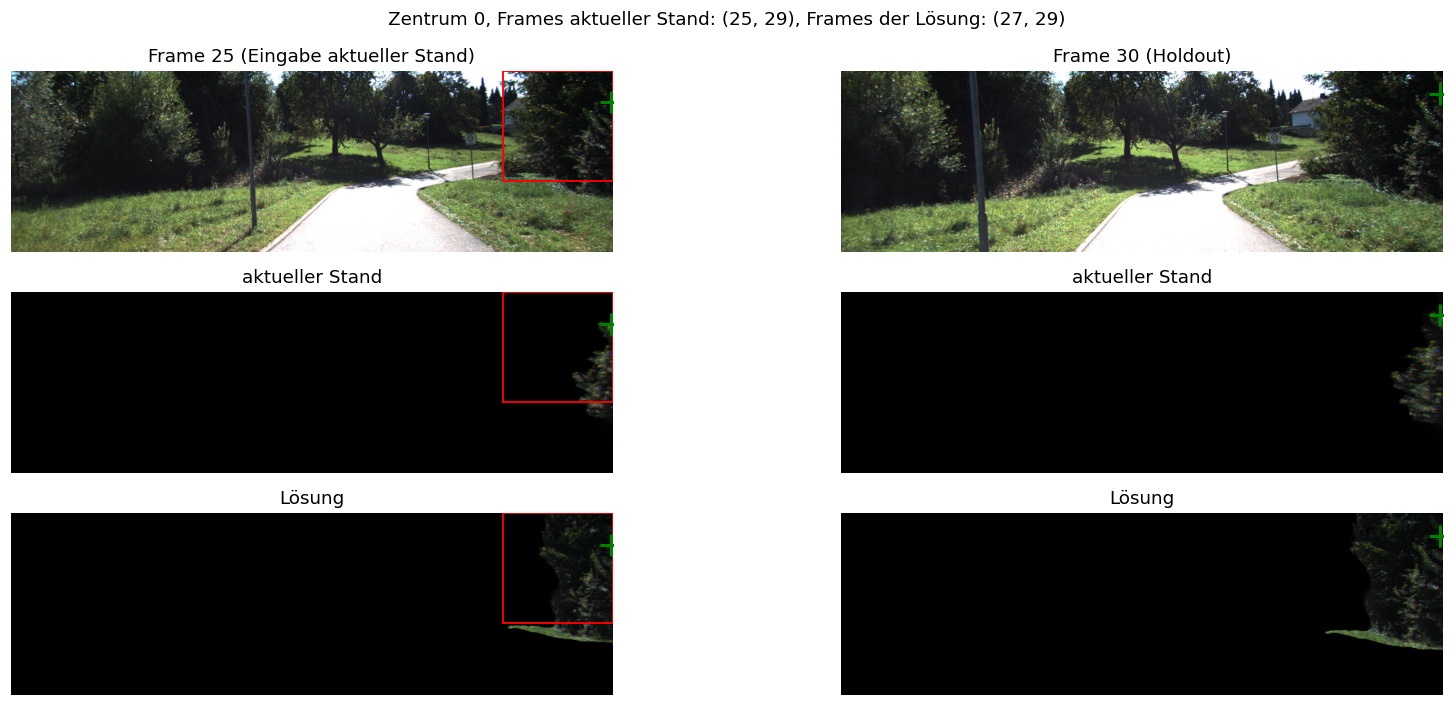

In [13]:
common = [j for j in INFO_B if j in INFO_L]
edge = max(common, key=lambda j: abs(UV[INFO_B[j]["ks"][0], j, 0] - K[0, 2]))
sub = lambda g, j: {key: (val[torch.from_numpy(g["cid"] == j)] if key == "harm" else val[g["cid"] == j])
                    for key, val in g.items()}
gB1, gL1 = sub(G_B, edge), sub(G_L, edge)
k_in = INFO_B[edge]["ks"][0]
vis_h = [k for k in EVAL if vis[k, edge]]
k_out = vis_h[len(vis_h) // 2] if vis_h else EVAL[0]
fig, ax = plt.subplots(3, 2, figsize=(16, 6.5))
for c, k in enumerate([k_in, k_out]):
    ax[0, c].imshow(images[k]); ax[0, c].set_title(f"Frame {k}" + (" (Eingabe aktueller Stand)" if k == k_in else " (Holdout)"))
    ax[1, c].imshow(render(gB1, k, depth=False)[0]); ax[1, c].set_title("aktueller Stand")
    ax[2, c].imshow(render(gL1, k, depth=False)[0]); ax[2, c].set_title("Lösung")
    for r in range(3):
        ax[r, c].plot(*project(centers[edge][None], k)[0][0], "g+", ms=14, mew=2)
        if k == k_in:
            c1 = INFO_B[edge]["crops"][0]
            ax[r, c].add_patch(patches.Rectangle((c1["x1"], c1["y1"]), 224, 224, fill=False, ec="r", lw=1.2))
        ax[r, c].set_xlim(0, W_IMG); ax[r, c].set_ylim(H_IMG, 0); ax[r, c].axis("off")
plt.suptitle(f"Zentrum {edge}, Frames aktueller Stand: {INFO_B[edge]['ks']}, Frames der Lösung: {INFO_L[edge]['ks']}")
plt.tight_layout(); plt.show()

### Was man in den Bildern sieht

**Straße (Frames 18 und 26).** Beim aktuellen Stand zerfällt die Straße in einzelne Platten, die gegeneinander verschoben und
verkippt sind. Jede Platte ist ein Zentrum, und jedes Zentrum liegt anders falsch. Im Farbfehler sieht man die
Kanten dieser Platten als helle Linien, im Tiefenfehler als Flächen mit 10 bis 30 %. Mit der Lösung läuft die Straße
durch. Farb- und Tiefenfehler sind dort fast überall dunkel.

**Büsche und Bäume.** Beim aktuellen Stand sitzen die Büsche im Tiefenfehler-Bild fast durchgehend bei 20 bis 30 % Fehler. Sie
stehen also deutlich vor oder hinter der Stelle, an der das Mesh sie hat. Mit der Lösung sind sie im Tiefenfehler schwarz,
weil jede Gaussian, deren Pixel das Mesh trifft, genau auf dem Mesh sitzt.

**Zentrum am Bildrand.** In der Einzelansicht oben liegt das Zentrum am rechten Rand. Vom aktuellen Stand bleibt nur ein
schmaler Streifen übrig. Die Drehung aus dem Skript schiebt den Patch neben die Stelle, an die er gehört, und der
größte Teil fällt aus der Kugel um das Zentrum heraus. Die Lösung legt Busch und Boden an die richtige Stelle, im
Eingabeframe genauso wie im Holdout-Frame.

**Frühe Frames (2, 6, 10).** Hier ist das PSNR von aktuellem Stand und Lösung etwa gleich. Das liegt daran, dass die Zentren in
diesen Frames meist nahe der Bildmitte liegen. Da ist die Drehung aus dem Skript fast richtig. Der Tiefenfehler des
aktuellen Stands liegt aber auch hier bei 12 bis 14 %, gegenüber 2 % bei der Lösung.

**Wo die Lösung noch schwach ist.** Große, verschwommene Gaussians, etwa im Gras in Frame 6 und unten links in Frame 18.
Sie kommen vom Rand der Crops, wo AnySplat unsicher ist. Dünne Strukturen, die im Mesh fehlen, wie das Straßenschild,
werden verschmiert, weil sie nur über die affine Korrektur platziert werden. Einen Filter für die großen Gaussians
habe ich getestet. Er macht es insgesamt schlechter, weil die Gaussians auch Lücken füllen.

### Warum das die Lösung ist

Das Problem im Skript hat drei Ursachen, und die Lösung behebt jede davon an der Wurzel statt mit einer Näherung:

1. **Der Crop ist nicht zentriert.** Der aktuelle Stand dreht nachträglich, und das stimmt nur in der Bildmitte (Test-Notebook:
   0,8 px Fehler in der Mitte, 10 bis 32 px am Rand). Die Lösung rektifiziert den Crop vorher. Damit stimmt AnySplats
   Annahme exakt.
2. **AnySplats relative Pose ist falsch.** AnySplat schätzt die Brennweite auf ungefähr die Hälfte der echten,
   weil ein KITTI-Crop viel schmaler ist als die Bilder, auf denen es trainiert wurde. Mit dieser Brennweite ist
   auch die relative Pose zwischen den beiden Ansichten falsch (Test-Notebook: 10 bis fast 400 px Fehler in
   Ansicht 2). Der aktuelle Stand verlässt sich darauf. Die Lösung nimmt für jede Ansicht die OKVIS-Pose, die ist bekannt und genau.
3. **AnySplats Tiefe ist ungenau.** Nach reiner Skalierung weicht sie im Median 5 bis 10 % vom Mesh ab. Der aktuelle Stand hat
   genau das: rund 12 % Tiefenfehler. Die Lösung setzt die Gaussians aufs Mesh und korrigiert den Rest mit einer affinen
   Abbildung. Das ergibt 2,4 % Tiefenfehler.

**Was das Nachoptimieren zeigt (Abschnitt 11).** Beim PSNR holt der aktuelle Stand nach dem Nachoptimieren fast auf, etwa 24 dB
gegenüber knapp 25 dB. Der Tiefenfehler des aktuellen Stands bleibt aber bei rund 11 %, der der Lösung bei gut 3 %. Die
Optimierung malt beim aktuellen Stand also die richtigen Farben auf die falsche Geometrie. Aus Blickwinkeln nahe den
Trainingsframes fällt das kaum auf. Sobald man die Gaussians mit dem OKVIS-Mesh zusammenbringen will, oder aus
einem anderen Winkel darauf schaut, ist es falsch. Um diese Geometrie geht es in der Pipeline, und die stimmt
nur bei der Lösung.

## 11. Optional: kurz nachoptimieren

Positionen, Farben (SH) und Deckkraft werden 1000 Schritte lang gegen die Trainingsframes optimiert, mit den echten
OKVIS-Posen und nur auf Mesh-Pixeln. Ein Zusatzterm hält die Gaussians in der Nähe ihrer Startposition. Die
Holdout-Frames werden dabei nicht benutzt.

Der aktuelle Stand wird genauso nachoptimiert, damit der Vergleich fair bleibt.

In [14]:
TRAIN_MASKS = {k: np.isfinite(mesh_depth(k)) for k in TRAIN}

def refine(g, iters=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    torch.set_grad_enabled(True)
    dev = DEVICE
    means = torch.tensor(g["means"], device=dev, requires_grad=True)
    anchor = means.detach().clone()
    cov = torch.tensor(g["cov"], device=dev)
    harm = g["harm"].to(dev).float().permute(0, 2, 1).contiguous().requires_grad_(True)
    op = torch.tensor(g["opac"], device=dev).clamp(1e-4, 1 - 1e-4)
    op_logit = torch.log(op / (1 - op)).requires_grad_(True)
    opt = torch.optim.Adam([{"params": [means], "lr": 1e-3}, {"params": [harm], "lr": 2.5e-3},
                            {"params": [op_logit], "lr": 2.5e-2}])
    Ks = torch.tensor(K, dtype=torch.float32, device=dev)[None]
    N = len(anchor)
    quats = torch.tensor([1.0, 0, 0, 0], device=dev).repeat(N, 1)
    ones = torch.ones(N, 3, device=dev)
    gts = {k: torch.tensor(images[k], dtype=torch.float32, device=dev) / 255 for k in TRAIN}
    masks = {k: torch.tensor(TRAIN_MASKS[k], device=dev) for k in TRAIN}
    views = {k: torch.tensor(np.linalg.inv(poses[k]), dtype=torch.float32, device=dev)[None] for k in TRAIN}
    for it in range(iters):
        k = TRAIN[rng.integers(len(TRAIN))]
        img, _, _ = rasterization(means=means, quats=quats, scales=ones, opacities=torch.sigmoid(op_logit),
                                  colors=harm, viewmats=views[k], Ks=Ks, width=W_IMG, height=H_IMG, sh_degree=4,
                                  covars=cov, near_plane=0.1, far_plane=500.0, packed=False, rasterize_mode="classic")
        loss = (img[0][masks[k]] - gts[k][masks[k]]).abs().mean() + 0.1 * ((means - anchor) ** 2).sum(1).mean()
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    torch.set_grad_enabled(False)
    out = dict(g)
    out["means"] = means.detach().cpu().numpy()
    out["harm"] = harm.detach().permute(0, 2, 1).contiguous().half().cpu()
    out["opac"] = torch.sigmoid(op_logit).detach().cpu().numpy()
    del means, anchor, cov, harm, op_logit, opt, gts, masks
    torch.cuda.empty_cache()
    print(f"Median-Verschiebung: {np.median(np.linalg.norm(out['means'] - g['means'], axis=1)) * 100:.1f} cm")
    return out

t = time.time(); G_Br = refine(G_B); print(f"aktueller Stand nachoptimiert in {time.time() - t:.0f} s")
t = time.time(); G_Lr = refine(G_L); print(f"Lösung nachoptimiert in {time.time() - t:.0f} s")
R_Br = evaluate(G_Br, "aktueller Stand + Nachopt.")
R_Lr = evaluate(G_Lr, "Lösung + Nachopt.")

Median-Verschiebung: 1.0 cm
aktueller Stand nachoptimiert in 34 s
Median-Verschiebung: 2.1 cm
Lösung nachoptimiert in 24 s
aktueller Stand + Nachopt.   PSNR 24.03 dB | Deckung 0.98 | Tiefenfehler 11.3 %
Lösung + Nachopt.            PSNR 24.61 dB | Deckung 0.98 | Tiefenfehler  3.4 %


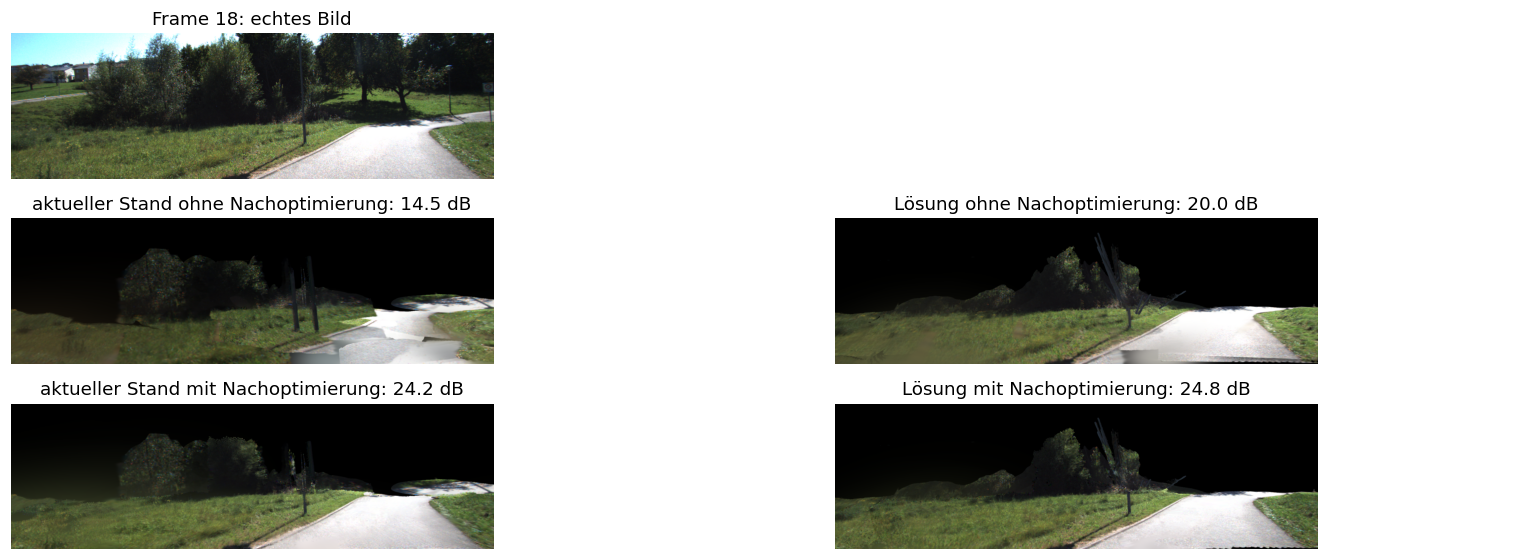

In [15]:
k = SHOW[1]
fig, ax = plt.subplots(3, 2, figsize=(16, 5.2))
ax[0, 0].imshow(images[k]); ax[0, 0].set_title(f"Frame {k}: echtes Bild")
ax[0, 1].axis("off")
for c, (name, R) in enumerate([("aktueller Stand", (R_B, R_Br)), ("Lösung", (R_L, R_Lr))]):
    for r, (lab, RR) in enumerate(zip(["ohne", "mit"], R), start=1):
        i = list(EVAL).index(k)
        ax[r, c].imshow(RR["renders"][k][0])
        ax[r, c].set_title(f"{name} {lab} Nachoptimierung: {RR['psnr'][i]:.1f} dB")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

## 12. Übertragen auf `intergratepipelines_gsrotations.py`

Die Funktionen aus diesem Notebook ersetzen im Skript:

| Skript | ersetzt durch |
|---|---|
| `project_centers()` | Sichtbarkeit aus Abschnitt 2 (mit `z > 0` und Verdeckungstest) |
| `crop_paths = sorted(...)[0], [-1]` | `frames_solution()` |
| `extract_window_no_padding()` + `process_image_helper()` | `rect_crop()` mit `adaptive_crop_size()` |
| `model.inference()` | `model.encoder(...)` mit `cfg.voxelize = False` |
| alles von Zeile 280 bis 571 (Rotationen, `z * 2`, `dscale`, `PoseOptimizer`) | `place_loesung()` |
| `export_ply(...)` pro Zentrum | Ergebnis von `place_loesung()` speichern, Rotationen per Eigenzerlegung von `cov` |
| `submap_gs_stitching_pipeline()` | `merge()` |

Die modifizierten Encoder-Hooks (`pixeldepth1`, `extrinsics1`, `intrinsicsfxy`) braucht die Lösung nicht. Sie
läuft mit dem unveränderten AnySplat.